In [10]:
import sys

sys.path.insert(1, '/home/isabela/Codes/flim-python')
from pyflim import metrics

from os import listdir, rename, path, makedirs
import pickle
from matplotlib import pyplot as plt
import os
import numpy as np
from IPython.display import display
import pandas as pd
import seaborn as sns
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

cm = sns.color_palette("crest", as_cmap=True)
cm_inv = sns.cubehelix_palette(start=.5, rot=-.75, reverse=True, as_cmap=True)

(48, 2)
(44, 2)
(102, 2)
2 48 44
(92, 2)


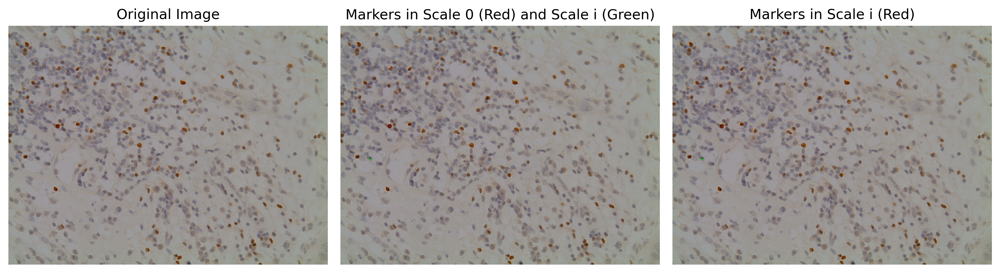

In [ ]:
# verifica se dois ou mais superpixels de uma mesma escala são parte de um superpixel maior em uma escala posterior

orig_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/imgs/orig/6.png'
spx_img_path1 = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/SH/60000/SUM/labels/6.pgm'
spx_img_path2 = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/SH/20000/SUM/labels/6.pgm'

orig_img = np.array(Image.open(orig_img_path))
spx_img1 = np.array(Image.open(spx_img_path1))
spx_img2 = np.array(Image.open(spx_img_path2))

# get pixels from superpixel

orig_copy1 = orig_img.copy()
pixels_union = []
for spx in [33904, 33483]:
    pixels = np.argwhere(spx_img1==spx)
    print(pixels.shape)
    orig_copy1[pixels[:, 0], pixels[:, 1]] = [0,255,0]
    pixels_union.append(pixels)

orig_copy2 = orig_img.copy()
pixels = np.argwhere(spx_img2==11566)
print(pixels.shape)
orig_copy2[pixels[:, 0], pixels[:, 1]] = [0,255,0]

# verifica se pixels_union estão dentro de pixels
print(len(pixels_union), len(pixels_union[0]), len(pixels_union[1]))
pixels_union = np.vstack(pixels_union)
print(pixels_union.shape)
for p in pixels_union:
    if not np.any(np.all(p == pixels, axis=1)):
        print('Pixel not found:', p)

fig = plt.figure(figsize=(12, 4), dpi=300)
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 1])
ax0 = plt.subplot(gs[0])
ax0.imshow(orig_img)
ax0.set_title('Original Image')
ax0.axis('off')
ax1 = plt.subplot(gs[1])
ax1.imshow(orig_copy1)
ax1.set_title('Markers in Scale 0 (Red) and Scale i (Green)')
ax1.axis('off')
ax2 = plt.subplot(gs[2])
ax2.imshow(orig_copy2)
ax2.set_title('Markers in Scale i (Red)')
ax2.axis('off')
plt.tight_layout()
plt.show()  

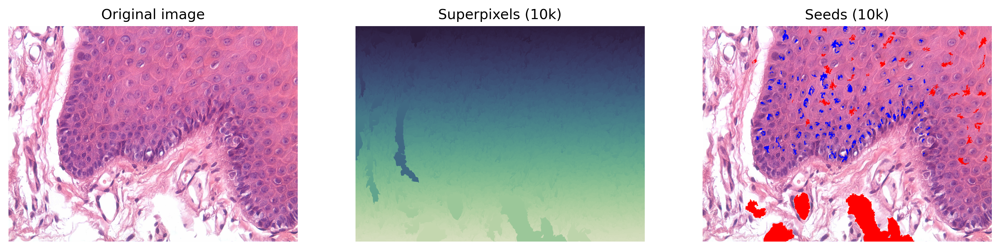

In [20]:
orig_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells2/interactive_splits/split1/orig/train/getIT_2.jpg'
spx_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells2/superpixels/SH/10000/SUM/labels/getIT_2.pgm'
markers_file = '/home/isabela/Codes/LibIFT/Results/cells2/split1/interactive/arch_cells4/gflim-BoFP-multiscale/graph-based/SH/40000-20000-10000/kmeans/SUM-NONE/markers_spx10000/getIT_2-seeds_graph.txt'

with open(markers_file, 'r') as f:
    lines = f.readlines()
    lines = [l.strip().split() for l in lines]
seeds = [tuple(map(int, l)) for l in lines[1:]]

orig_img = np.array(Image.open(orig_img_path))
spx_img = np.array(Image.open(spx_img_path))
orig_copy = orig_img.copy()
for spx,m,l in seeds:
    if l == 0:
        orig_copy[spx_img==spx+1] = [255,0,0]
    else:
        orig_copy[spx_img==spx+1] = [0,0,255]

plt.figure(figsize=(15,5), dpi=300)
plt.subplot(1,3,1)
plt.imshow(orig_img)
plt.title('Original image')
plt.axis('off')
plt.subplot(1,3,2)
plt.imshow(spx_img, cmap=cm_inv)
plt.title('Superpixels (10k)')
plt.axis('off')
plt.subplot(1,3,3)
plt.imshow(orig_copy)
plt.title('Seeds (10k)')
plt.axis('off')
plt.show()

### Selecting one marker per iteration based only on the Euclidean distance

In [ ]:
# read results

DATASET_PATH = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset'
DS_NAME = DATASET_PATH.split('/')[-1]
MARKERS_NAME = 'automatic_markers'
STRIDE = 'graph-based'
SPX_ALG = 'DISF'
INIT_SEEDS = 50000
FINAL_SPX = 20000
GRAPH_FEATS = 'SUM'
ATTENTION = 'NONE'
AGGREGATION = 'CONCAT'
CONFIG = 'kmeans'
ARCH_NAME = 'arch_cells4'
SPLIT_ID = 5

last_layer = 1
data = {}
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}'  
    
for img_set in ['train', 'val']:
    orig_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/orig/{img_set}"
    gt_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/label/{img_set}"

    for iteration in range(1, 20):
        data[iteration] = {}

        for last_layer in range(1,4):
            data[iteration][last_layer] = {}
            
            for DECODER in ["hybrid", "graph-adaptive"]:
                save_file = f'{model_dir}/results_byDistance/iteration_{iteration}/{img_set}_{DECODER}_{last_layer}.pkl'
                with open(save_file, 'rb') as file:
                    data[iteration][last_layer][DECODER] = pickle.load(file)

In [ ]:
# convert results in data to Dataframe

def load_data(data_pd, v3):
    if(v3.computed_detection_metrics):
        data_pd['uF-M⁵'].append(v3.fscore["0.5"])
        data_pd['mAP⁵'].append(v3.ap["0.5"])
        data_pd['uF-M⁷⁵'].append(v3.fscore["0.75"])
        data_pd['mAP⁷⁵'].append(v3.ap["0.75"])
        data_pd['muAP'].append(v3.mu_ap)
    else:
        data_pd['uF-M⁵'].append(np.nan)
        data_pd['mAP⁵'].append(np.nan)
        data_pd['uF-M⁷⁵'].append(np.nan)
        data_pd['mAP⁷⁵'].append(np.nan)
        data_pd['muAP'].append(np.nan)

    if(v3.computed_saliency_metrics):
        data_pd['uWF-M'].append(v3.wfscore.mean())
        data_pd['MAE'].append(v3.mae.mean())
        if(v3.use_smeasure):
            data_pd['S-M'].append(v3.smeasure.mean())
        else:
            data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(v3.emeasure.mean())
        data_pd['DICE'].append(v3.dices.mean())
    else:
        data_pd['uWF-M'].append(np.nan)
        data_pd['MAE'].append(np.nan)
        data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(np.nan)
        data_pd['DICE'].append(np.nan)

data_tmp = {'Iteration': [], 'Layer': [], 'Decoder': [], 'uF-M⁵': [], 'mAP⁵': [], 'uF-M⁷⁵': [], 'mAP⁷⁵': [], 'muAP': [], 'uWF-M': [], 'MAE': [], 'S-M': [], 'E-M': [], 'DICE': []}
for iteration,v1 in data.items():
    for layer,v2 in v1.items():
        for decoder,v3 in v2.items():
            data_tmp['Iteration'].append(iteration)
            data_tmp['Layer'].append(layer)
            data_tmp['Decoder'].append(decoder)
            load_data(data_tmp, v3)

data_pd = pd.DataFrame(data_tmp)
display(data_pd)

,Iteration,Layer,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
0,1,1,hybrid,0.026810,0.246375,0.006702,0.060528,0.155848,0.006114,13.763965,0.459708,0.254633,0.007515
1,1,1,graphadaptive,0.170708,0.192581,0.069273,0.010762,0.105670,0.096301,48.667227,0.417080,0.320818,0.116177
2,1,2,hybrid,0.021277,0.184510,0.007092,0.060617,0.122801,0.005742,16.181428,0.456578,0.253879,0.007286
3,1,2,graphadaptive,0.211138,0.101225,0.100979,0.045883,0.060481,0.111251,34.198163,0.453296,0.365073,0.132933
4,1,3,hybrid,0.101966,0.095476,0.032775,0.017782,0.049481,0.058222,19.198759,0.460561,0.321662,0.069865
...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,19,1,graphadaptive,0.000000,0.000000,0.000000,0.000000,0.000000,0.030028,228.828076,0.075389,0.122498,0.038770
110,19,2,hybrid,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.018263,0.490869,0.250000,0.000000
111,19,2,graphadaptive,0.000000,0.000000,0.000000,0.000000,0.000000,0.030186,228.103058,0.077349,0.126993,0.038968
112,19,3,hybrid,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.018263,0.490869,0.250000,0.000000


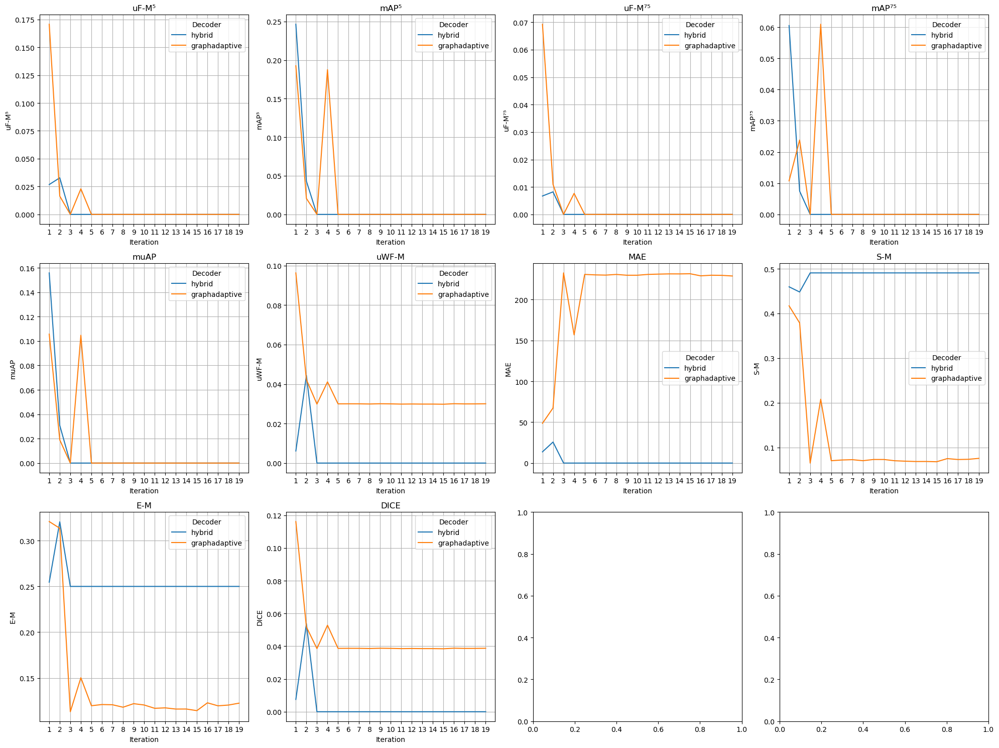

In [ ]:
# plot results with x-axis as iteration and y-axis as metrics

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
titles = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
for i, metric in enumerate(metrics):
    layer = 1
    sns.lineplot(data=data_pd[data_pd['Layer'] == layer], x='Iteration', y=metric, hue='Decoder', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Iteration')
    axes[i].set_ylabel(metric)
    axes[i].grid(True)
    axes[i].set_xticks(range(1, data_pd['Iteration'].max()+1, 1))
    #axes[i].set_yticks(np.arange(0, data_pd[metric].max()+0.1, 0.1))

plt.tight_layout()

### Selecting pairs of markers per iteration based only on the Euclidean distance (avoid neighbors)

In [ ]:
# read results

DATASET_PATH = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset'
DS_NAME = DATASET_PATH.split('/')[-1]
MARKERS_NAME = 'automatic_markers'
STRIDE = 'graph-based'
SPX_ALG = 'DISF'
INIT_SEEDS = 50000
FINAL_SPX = 20000
GRAPH_FEATS = 'SUM'
ATTENTION = 'NONE'
AGGREGATION = 'CONCAT'
CONFIG = 'kmeans'
ARCH_NAME = 'arch_cells4'
SPLIT_ID = 5

last_layer = 1
data = {}
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}'  
    
for img_set in ['train', 'val']:
    orig_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/orig/{img_set}"
    gt_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/label/{img_set}"

    for iteration in range(1, 10):
        data[iteration] = {}

        for last_layer in range(1,4):
            data[iteration][last_layer] = {}
            
            for DECODER in ["hybrid", "graph-adaptive"]:
                save_file = f'{model_dir}/results_pairs_avoidNeighbors/iteration_{iteration}/{img_set}_{DECODER}_{last_layer}.pkl'
                with open(save_file, 'rb') as file:
                    data[iteration][last_layer][DECODER] = pickle.load(file)

In [11]:
# convert results in data to Dataframe

def load_data(data_pd, v3):
    if(v3.computed_detection_metrics):
        data_pd['uF-M⁵'].append(v3.fscore["0.5"])
        data_pd['mAP⁵'].append(v3.ap["0.5"])
        data_pd['uF-M⁷⁵'].append(v3.fscore["0.75"])
        data_pd['mAP⁷⁵'].append(v3.ap["0.75"])
        data_pd['muAP'].append(v3.mu_ap)
    else:
        data_pd['uF-M⁵'].append(np.nan)
        data_pd['mAP⁵'].append(np.nan)
        data_pd['uF-M⁷⁵'].append(np.nan)
        data_pd['mAP⁷⁵'].append(np.nan)
        data_pd['muAP'].append(np.nan)

    if(v3.computed_saliency_metrics):
        data_pd['uWF-M'].append(v3.wfscore.mean())
        data_pd['MAE'].append(v3.mae.mean())
        if(v3.use_smeasure):
            data_pd['S-M'].append(v3.smeasure.mean())
        else:
            data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(v3.emeasure.mean())
        data_pd['DICE'].append(v3.dices.mean())
    else:
        data_pd['uWF-M'].append(np.nan)
        data_pd['MAE'].append(np.nan)
        data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(np.nan)
        data_pd['DICE'].append(np.nan)

data_tmp = {'Iteration': [], 'Layer': [], 'Decoder': [], 'uF-M⁵': [], 'mAP⁵': [], 'uF-M⁷⁵': [], 'mAP⁷⁵': [], 'muAP': [], 'uWF-M': [], 'MAE': [], 'S-M': [], 'E-M': [], 'DICE': []}
for iteration,v1 in data.items():
    for layer,v2 in v1.items():
        for decoder,v3 in v2.items():
            data_tmp['Iteration'].append(iteration)
            data_tmp['Layer'].append(layer)
            data_tmp['Decoder'].append(decoder)
            load_data(data_tmp, v3)

data_pd = pd.DataFrame(data_tmp)
display(data_pd)

,Iteration,Layer,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
0,1,1,hybrid,0.026810,0.246375,0.006702,0.060528,0.155848,0.006114,13.763965,0.459708,0.254633,0.007515
1,1,1,graphadaptive,0.170708,0.192581,0.069273,0.010762,0.105670,0.096301,48.667227,0.417080,0.320818,0.116177
2,1,2,hybrid,0.021277,0.184510,0.007092,0.060617,0.122801,0.005742,16.181428,0.456578,0.253879,0.007286
3,1,2,graphadaptive,0.211138,0.101225,0.100979,0.045883,0.060481,0.111251,34.198163,0.453296,0.365073,0.132933
4,1,3,hybrid,0.101966,0.095476,0.032775,0.017782,0.049481,0.058222,19.198759,0.460561,0.321662,0.069865
5,1,3,graphadaptive,0.139398,0.014542,0.047689,0.011154,0.017674,0.098071,22.054305,0.469760,0.460015,0.117706
6,2,1,hybrid,0.112872,0.073545,0.048031,0.029989,0.054148,0.061235,15.787916,0.453534,0.479522,0.071334
7,2,1,graphadaptive,0.047101,0.319484,0.010870,0.092471,0.192895,0.040535,49.396070,0.400348,0.315396,0.050644
8,2,2,hybrid,0.039746,0.016359,0.019873,0.009519,0.013329,0.024692,5.412535,0.464888,0.756850,0.027561
9,2,2,graphadaptive,0.083565,0.134278,0.031337,0.051871,0.094521,0.057942,8.812726,0.468425,0.647436,0.066489


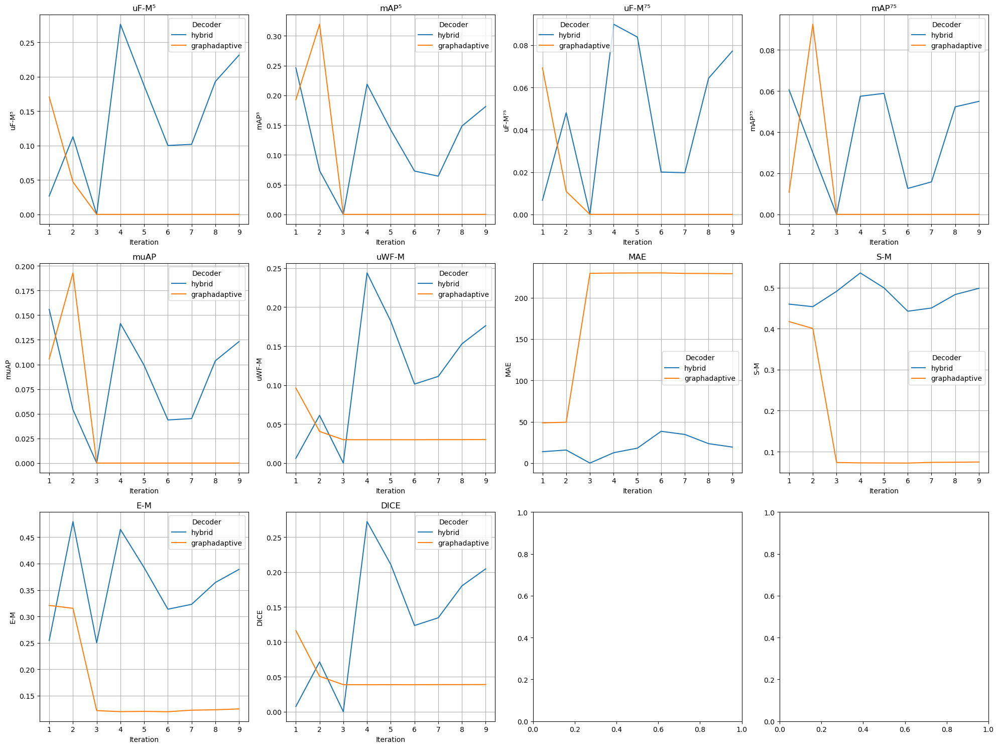

In [12]:
# plot results with x-axis as iteration and y-axis as metrics

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
titles = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
for i, metric in enumerate(metrics):
    layer = 1
    sns.lineplot(data=data_pd[data_pd['Layer'] == layer], x='Iteration', y=metric, hue='Decoder', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Iteration')
    axes[i].set_ylabel(metric)
    axes[i].grid(True)
    axes[i].set_xticks(range(1, data_pd['Iteration'].max()+1, 1))
    #axes[i].set_yticks(np.arange(0, data_pd[metric].max()+0.1, 0.1))

plt.tight_layout()

### Selecting pairs of markers per iteration based only on the Euclidean distance (avoid neighbors)

In [11]:
# read results

DATASET_PATH = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset'
DS_NAME = DATASET_PATH.split('/')[-1]
MARKERS_NAME = 'automatic_markers'
STRIDE = 'graph-based'
SPX_ALG = 'DISF'
INIT_SEEDS = 50000
FINAL_SPX = 20000
GRAPH_FEATS = 'SUM'
ATTENTION = 'NONE'
AGGREGATION = 'CONCAT'
CONFIG = 'kmeans'
ARCH_NAME = 'arch_cells4'
SPLIT_ID = 5

last_layer = 1
data = {}
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}'  
    
for img_set in ['train', 'val']:
    orig_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/orig/{img_set}"
    gt_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/label/{img_set}"

    for iteration in range(1, 10):
        data[iteration] = {}

        for last_layer in range(1,4):
            data[iteration][last_layer] = {}
            
            for DECODER in ["hybrid", "graph-adaptive"]:
                save_file = f'{model_dir}/results_pairs_avoidNeighbors_std_distanceFromAllMarkers/iteration_{iteration}/{img_set}_{DECODER}_{last_layer}.pkl'
                with open(save_file, 'rb') as file:
                    data[iteration][last_layer][DECODER] = pickle.load(file)

FileNotFoundError: [Errno 2] No such file or directory: '/home/isabela/Codes/LibIFT/Results/cells_dataset/split5/automatic_markers/arch_cells4/gflim-BoFP/graph-based/DISF/50000-20000/kmeans/SUM-NONE/results_pairs_avoidNeighbors_std_distanceFromAllMarkers/iteration_1/train_hybrid_1.pkl'

In [14]:
# convert results in data to Dataframe

def load_data(data_pd, v3):
    if(v3.computed_detection_metrics):
        data_pd['uF-M⁵'].append(v3.fscore["0.5"])
        data_pd['mAP⁵'].append(v3.ap["0.5"])
        data_pd['uF-M⁷⁵'].append(v3.fscore["0.75"])
        data_pd['mAP⁷⁵'].append(v3.ap["0.75"])
        data_pd['muAP'].append(v3.mu_ap)
    else:
        data_pd['uF-M⁵'].append(np.nan)
        data_pd['mAP⁵'].append(np.nan)
        data_pd['uF-M⁷⁵'].append(np.nan)
        data_pd['mAP⁷⁵'].append(np.nan)
        data_pd['muAP'].append(np.nan)

    if(v3.computed_saliency_metrics):
        data_pd['uWF-M'].append(v3.wfscore.mean())
        data_pd['MAE'].append(v3.mae.mean())
        if(v3.use_smeasure):
            data_pd['S-M'].append(v3.smeasure.mean())
        else:
            data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(v3.emeasure.mean())
        data_pd['DICE'].append(v3.dices.mean())
    else:
        data_pd['uWF-M'].append(np.nan)
        data_pd['MAE'].append(np.nan)
        data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(np.nan)
        data_pd['DICE'].append(np.nan)

data_tmp = {'Iteration': [], 'Layer': [], 'Decoder': [], 'uF-M⁵': [], 'mAP⁵': [], 'uF-M⁷⁵': [], 'mAP⁷⁵': [], 'muAP': [], 'uWF-M': [], 'MAE': [], 'S-M': [], 'E-M': [], 'DICE': []}
for iteration,v1 in data.items():
    for layer,v2 in v1.items():
        for decoder,v3 in v2.items():
            data_tmp['Iteration'].append(iteration)
            data_tmp['Layer'].append(layer)
            data_tmp['Decoder'].append(decoder)
            load_data(data_tmp, v3)

data_pd = pd.DataFrame(data_tmp)
display(data_pd)

,Iteration,Layer,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
0,1,1,hybrid,0.454783,0.120977,0.313643,0.121839,0.097212,0.184314,23.875013,0.531787,0.498530,0.209046
1,1,1,graphadaptive,0.457729,0.148406,0.305153,0.079973,0.094876,0.215862,14.767460,0.547219,0.498161,0.244613
2,1,2,hybrid,0.190904,0.040422,0.106682,0.010517,0.028727,0.100381,29.508540,0.450055,0.459503,0.117036
3,1,2,graphadaptive,0.191310,0.042167,0.110246,0.014219,0.028054,0.131449,19.786169,0.488057,0.639752,0.150802
4,1,3,hybrid,0.000000,0.000000,0.000000,0.000000,0.002164,0.002798,21.544887,0.449924,0.252461,0.003623
5,1,3,graphadaptive,0.038488,0.003611,0.017495,0.004056,0.003769,0.049326,92.099800,0.340466,0.271471,0.061849
6,2,1,hybrid,0.087765,0.160392,0.028394,0.051328,0.115152,0.019997,24.354783,0.442173,0.371157,0.021554
7,2,1,graphadaptive,0.000000,0.000000,0.000000,0.000000,0.000000,0.029783,227.688860,0.077641,0.130488,0.038127
8,2,2,hybrid,0.056225,0.067539,0.008032,0.009335,0.042122,0.018478,5.718981,0.467604,0.664993,0.019522
9,2,2,graphadaptive,0.035294,0.001786,0.007843,0.003742,0.002008,0.025982,133.770634,0.267688,0.254423,0.032298


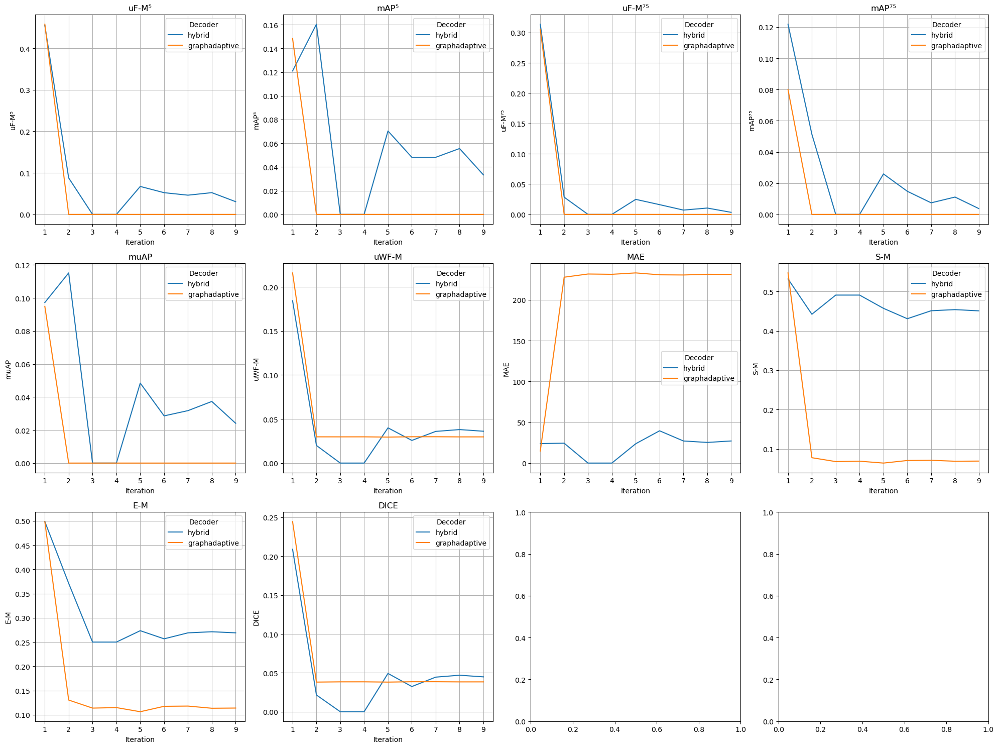

In [15]:
# plot results with x-axis as iteration and y-axis as metrics

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
titles = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
for i, metric in enumerate(metrics):
    layer = 1
    sns.lineplot(data=data_pd[data_pd['Layer'] == layer], x='Iteration', y=metric, hue='Decoder', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Iteration')
    axes[i].set_ylabel(metric)
    axes[i].grid(True)
    axes[i].set_xticks(range(1, data_pd['Iteration'].max()+1, 1))
    #axes[i].set_yticks(np.arange(0, data_pd[metric].max()+0.1, 0.1))

plt.tight_layout()

### Selecting pairs of markers per iteration based only on the Euclidean distance with manual removal (avoid neighbors)

In [15]:
# read results

DATASET_PATH = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset'
DS_NAME = DATASET_PATH.split('/')[-1]
MARKERS_NAME = 'automatic_markers'
STRIDE = 'graph-based'
SPX_ALG = 'DISF'
INIT_SEEDS = 50000
FINAL_SPX = 20000
GRAPH_FEATS = 'SUM'
ATTENTION = 'NONE'
AGGREGATION = 'CONCAT'
CONFIG = 'kmeans'
ARCH_NAME = 'arch_cells4'
SPLIT_ID = 5

last_layer = 1
data = {}
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}-{AGGREGATION}'  
    
for img_set in ['train', 'val']:
    orig_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/orig/{img_set}"
    gt_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/label/{img_set}"

    data[img_set] = {}
    for iteration in range(1, 30):
            data[img_set][iteration] = {}

            for DECODER in ["hybrid", "graph-adaptive"]:
                save_file = f'{model_dir}/results_semi_automatic_euclDist_std/iteration_{iteration}/{img_set}_{DECODER}_{last_layer}.pkl'
                with open(save_file, 'rb') as file:
                    data[img_set][iteration][DECODER] = pickle.load(file)

In [16]:
# convert results in data to Dataframe

def load_data(data_pd, v3):
    if(v3.computed_detection_metrics):
        data_pd['uF-M⁵'].append(v3.fscore["0.5"])
        data_pd['mAP⁵'].append(v3.ap["0.5"])
        data_pd['uF-M⁷⁵'].append(v3.fscore["0.75"])
        data_pd['mAP⁷⁵'].append(v3.ap["0.75"])
        data_pd['muAP'].append(v3.mu_ap)
    else:
        data_pd['uF-M⁵'].append(np.nan)
        data_pd['mAP⁵'].append(np.nan)
        data_pd['uF-M⁷⁵'].append(np.nan)
        data_pd['mAP⁷⁵'].append(np.nan)
        data_pd['muAP'].append(np.nan)

    if(v3.computed_saliency_metrics):
        data_pd['uWF-M'].append(v3.wfscore.mean())
        data_pd['MAE'].append(v3.mae.mean())
        if(v3.use_smeasure):
            data_pd['S-M'].append(v3.smeasure.mean())
        else:
            data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(v3.emeasure.mean())
        data_pd['DICE'].append(v3.dices.mean())
    else:
        data_pd['uWF-M'].append(np.nan)
        data_pd['MAE'].append(np.nan)
        data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(np.nan)
        data_pd['DICE'].append(np.nan)

data_tmp = {'ImgSet': [], 'Iteration': [], 'Decoder': [], 'uF-M⁵': [], 'mAP⁵': [], 'uF-M⁷⁵': [], 'mAP⁷⁵': [], 'muAP': [], 'uWF-M': [], 'MAE': [], 'S-M': [], 'E-M': [], 'DICE': []}
for imgSet,v1 in data.items():
    for iteration,v2 in v1.items():
        for decoder,v3 in v2.items():
            data_tmp['ImgSet'].append(imgSet)
            data_tmp['Iteration'].append(iteration)
            data_tmp['Decoder'].append(decoder)
            load_data(data_tmp, v3)

data_pd = pd.DataFrame(data_tmp)
display(data_pd)

,ImgSet,Iteration,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
0,train,1,hybrid,0.302768,0.238464,0.138408,0.101535,0.172283,0.083351,19.638673,0.468147,0.411630,0.095060
1,train,1,graph-adaptive,0.253623,0.228931,0.101449,0.086629,0.168788,0.109893,22.941550,0.476225,0.384172,0.127867
2,train,2,hybrid,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012723,0.493638,0.250000,0.000000
3,train,2,graph-adaptive,0.010438,0.005994,0.000000,0.000000,0.004739,0.042456,110.573415,0.313341,0.264090,0.054662
4,train,3,hybrid,0.157303,0.094037,0.089888,0.051114,0.069236,0.108276,6.216457,0.511310,0.769377,0.122942
...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,val,27,graph-adaptive,0.000000,0.000000,0.000000,0.000000,0.000000,0.031076,220.687973,0.096985,0.149978,0.040085
112,val,28,hybrid,0.303222,0.227254,0.110550,0.071464,0.151545,0.227710,19.738057,0.507220,0.428573,0.268656
113,val,28,graph-adaptive,0.000000,0.000000,0.000000,0.000000,0.000000,0.032021,213.825199,0.114332,0.168076,0.041263
114,val,29,hybrid,0.261628,0.102207,0.087209,0.018915,0.068719,0.206600,24.779851,0.492956,0.416918,0.240187


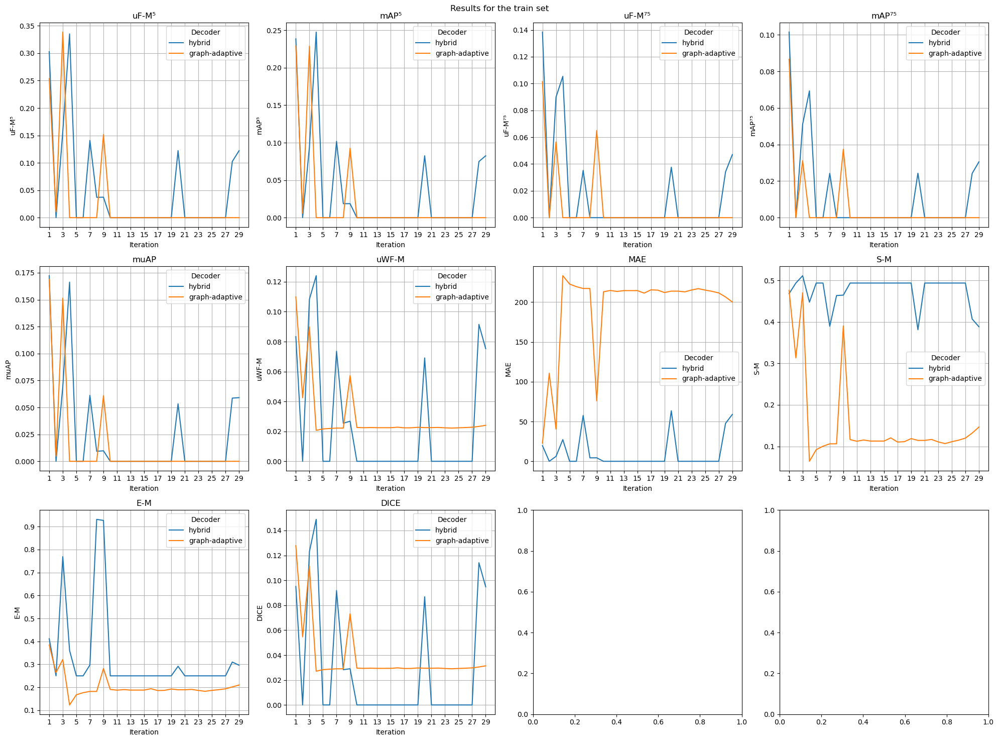

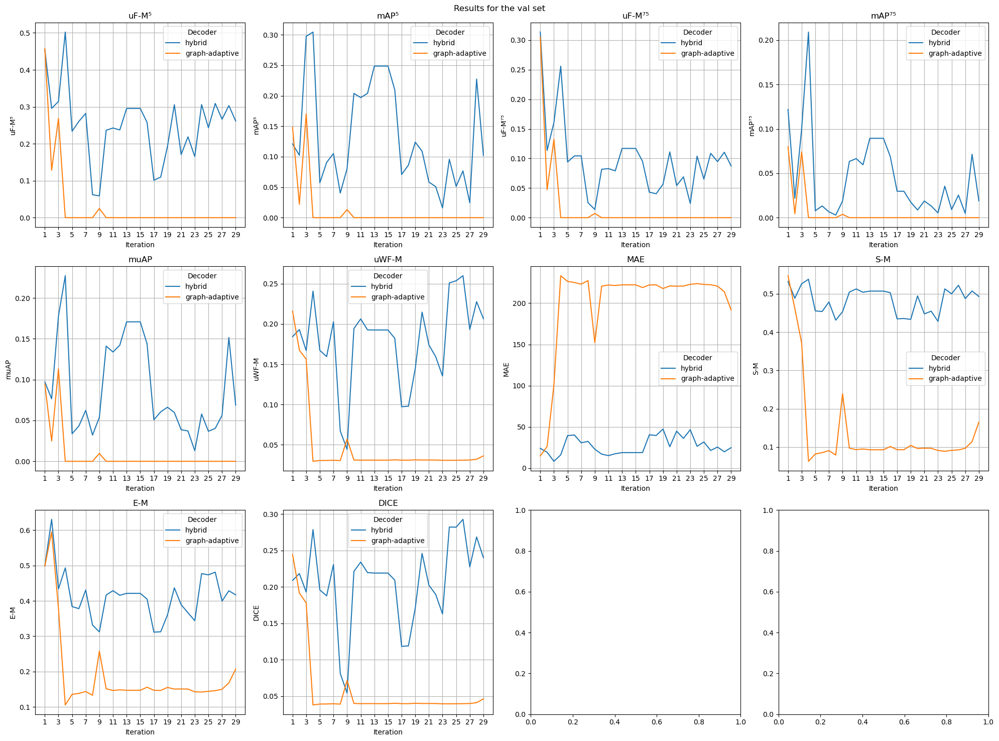

In [17]:
# plot results with x-axis as iteration and y-axis as metrics

# plot results for train set
subset = data_pd[(data_pd['ImgSet'] == 'train')]
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
titles = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
for i, metric in enumerate(metrics):
    layer = 1
    sns.lineplot(data=subset, x='Iteration', y=metric, hue='Decoder', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Iteration')
    axes[i].set_ylabel(metric)
    axes[i].grid(True)
    axes[i].set_xticks(range(1, subset['Iteration'].max()+1, 2))

# show title with the name of the dataset
plt.suptitle('Results for the train set')
plt.tight_layout()

# plot results for val set
subset = data_pd[(data_pd['ImgSet'] == 'val')]
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
titles = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']
for i, metric in enumerate(metrics):
    layer = 1
    sns.lineplot(data=subset, x='Iteration', y=metric, hue='Decoder', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Iteration')
    axes[i].set_ylabel(metric)
    axes[i].grid(True)
    axes[i].set_xticks(range(1, subset['Iteration'].max()+1, 2))

# show title with the name of the dataset
plt.suptitle('Results for the val set')
plt.tight_layout()

In [5]:
metrics = ['uF-M⁵', 'mAP⁵', 'uF-M⁷⁵', 'mAP⁷⁵', 'muAP', 'uWF-M', 'MAE', 'S-M', 'E-M', 'DICE']

subset = data_pd[(data_pd['Decoder'] == 'hybrid') & (data_pd['ImgSet'] == 'val')]
summary_data = []
for i, metric in enumerate(metrics):
    # get which iterations the value increase, decrease, or maintain
    improve, worsen, maintain = [], [], []
    for it in range(2, subset['Iteration'].max()+1):
        curr_val = subset[(subset['Iteration'] == it)][metric]
        prev_val = subset[(subset['Iteration'] == it-1)][metric]
        if curr_val.values[0] > prev_val.values[0]:
            improve.append(it)
        elif curr_val.values[0] < prev_val.values[0]:
            worsen.append(it)
        else:
            maintain.append(it)

    best_value = subset[metric].max() if metric != 'MAE' else subset[metric].min()
    best_iteration = subset[subset[metric] == best_value]['Iteration'].values[0]
    summary_data.append({
        'Metric': metric,
        'Improve': improve if metric != 'MAE' else worsen,  # For MAE, we consider worsening as improvement
        'Worsen': worsen if metric != 'MAE' else improve,  # For MAE, we consider improvement as worsening
        'Maintain': maintain,
        'Best Value': best_value,
        'Best Iteration': best_iteration
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Metric,Improve,Worsen,Maintain,Best Value,Best Iteration
0,uF-M⁵,[3],"[2, 4]",[],0.454783,1
1,mAP⁵,[3],"[2, 4]",[],0.297435,3
2,uF-M⁷⁵,[3],"[2, 4]",[],0.313643,1
3,mAP⁷⁵,[3],"[2, 4]",[],0.121839,1
4,muAP,[3],"[2, 4]",[],0.177890,3
5,uWF-M,[2],"[3, 4]",[],0.193115,2
6,MAE,"[2, 3]",[4],[],8.188746,3
7,S-M,[3],"[2, 4]",[],0.531787,1
8,E-M,[2],"[3, 4]",[],0.630493,2
9,DICE,[2],"[3, 4]",[],0.218366,2


In [ ]:
sys.path.insert(1, '/home/isabela/Codes/flim-python')
from pyflim import metrics

def evaluate(layer : int, model_dir : str, save_path : str, img_folder : str, labels_folder : str):
    for d in ["graph-adaptive", "hybrid"]:
        save_file = f'{save_path}_{d}_{layer}.pkl'
        saliency_dir = f"{model_dir}/{d}_{layer}/label2"

        metricas = metrics.FLIMMetrics(use_smeasure=True)
        metricas.evaluate_saliency_results(saliency_dir, labels_folder, file_list=[file.split('.')[0] for file in os.listdir(img_folder)])
        metricas.evaluate_detection_results(saliency_dir, labels_folder, file_list=[file.split('.')[0] for file in os.listdir(img_folder)])

        print('Saving metrics to file:', save_file)
        if not os.path.exists(os.path.dirname(save_file)):
            os.makedirs(os.path.dirname(save_file), exist_ok=True)
        with open(save_file, 'wb') as file:
            pickle.dump(metricas, file)

original_image_path = os.path.join(DATASET_PATH, 'automatic_splits', f'split{SPLIT_ID}', 'orig')
labels_path = os.path.join(DATASET_PATH, 'automatic_splits', f'split{SPLIT_ID}', 'label')
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}'
save_path = model_dir
evaluate(layer, model_dir, os.path.join(save_path,'val'), os.path.join(original_image_path, 'val'), os.path.join(labels_path, 'val'))

Saving metrics to file: /home/isabela/Codes/LibIFT/Results/cells_dataset/split5/automatic_markers/arch_cells4/gflim-BoFP/graph-based/DISF/50000-20000/kmeans/SUM-NONE/val_graphadaptive_1.pkl
Saving metrics to file: /home/isabela/Codes/LibIFT/Results/cells_dataset/split5/automatic_markers/arch_cells4/gflim-BoFP/graph-based/DISF/50000-20000/kmeans/SUM-NONE/val_hybrid_1.pkl


In [ ]:
last_layer = 1
data2 = {}
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}/results_semi_automatic/iteration_3'  
    
# read results
for img_set in ['val']:
    orig_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/orig/{img_set}"
    gt_folder = f"{DATASET_PATH}/splits/split{SPLIT_ID}/label/{img_set}"

    data2[img_set] = {}

    for DECODER in ["hybrid", "graph-adaptive"]:
        save_file = f'{model_dir}/{img_set}_{DECODER}_{last_layer}.pkl'
        with open(save_file, 'rb') as file:
            data2[img_set][DECODER] = pickle.load(file)


# convert results in data to Dataframe
def load_data(data_pd, v3):
    if(v3.computed_detection_metrics):
        data_pd['uF-M⁵'].append(v3.fscore["0.5"])
        data_pd['mAP⁵'].append(v3.ap["0.5"])
        data_pd['uF-M⁷⁵'].append(v3.fscore["0.75"])
        data_pd['mAP⁷⁵'].append(v3.ap["0.75"])
        data_pd['muAP'].append(v3.mu_ap)
    else:
        data_pd['uF-M⁵'].append(np.nan)
        data_pd['mAP⁵'].append(np.nan)
        data_pd['uF-M⁷⁵'].append(np.nan)
        data_pd['mAP⁷⁵'].append(np.nan)
        data_pd['muAP'].append(np.nan)

    if(v3.computed_saliency_metrics):
        data_pd['uWF-M'].append(v3.wfscore.mean())
        data_pd['MAE'].append(v3.mae.mean())
        if(v3.use_smeasure):
            data_pd['S-M'].append(v3.smeasure.mean())
        else:
            data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(v3.emeasure.mean())
        data_pd['DICE'].append(v3.dices.mean())
    else:
        data_pd['uWF-M'].append(np.nan)
        data_pd['MAE'].append(np.nan)
        data_pd['S-M'].append(np.nan)
        data_pd['E-M'].append(np.nan)
        data_pd['DICE'].append(np.nan)

data_tmp = {'ImgSet': [], 'Decoder': [], 'uF-M⁵': [], 'mAP⁵': [], 'uF-M⁷⁵': [], 'mAP⁷⁵': [], 'muAP': [], 'uWF-M': [], 'MAE': [], 'S-M': [], 'E-M': [], 'DICE': []}
for imgSet,v1 in data2.items():
    for decoder,v2 in v1.items():
            data_tmp['ImgSet'].append(imgSet)
            data_tmp['Decoder'].append(decoder)
            load_data(data_tmp, v2)

data2_pd = pd.DataFrame(data_tmp)
display(data2_pd)

,ImgSet,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
0,val,hybrid,0.314286,0.297435,0.160714,0.100102,0.177890,0.166962,8.188746,0.526229,0.433609,0.193098
1,val,graphadaptive,0.268533,0.170057,0.132375,0.074189,0.113235,0.156319,101.019112,0.371412,0.378883,0.178175


In [7]:
display(data_pd[((data_pd['Iteration'] == 3) | (data_pd['Iteration'] == 2)) & (data_pd['ImgSet'] == 'val')])

,ImgSet,Iteration,Decoder,uF-M⁵,mAP⁵,uF-M⁷⁵,mAP⁷⁵,muAP,uWF-M,MAE,S-M,E-M,DICE
10,val,2,hybrid,0.295827,0.102254,0.113576,0.021852,0.076599,0.193115,19.196426,0.488490,0.630493,0.218366
11,val,2,graphadaptive,0.128474,0.021860,0.047195,0.004389,0.024888,0.167443,26.145908,0.461464,0.594822,0.191680
12,val,3,hybrid,0.314286,0.297435,0.160714,0.100102,0.177890,0.166962,8.188746,0.526229,0.433609,0.193098
13,val,3,graphadaptive,0.268533,0.170057,0.132375,0.074189,0.113235,0.156319,101.019112,0.371412,0.378883,0.178175


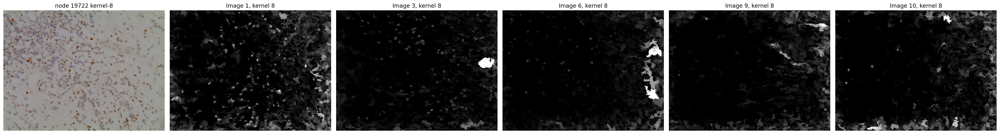

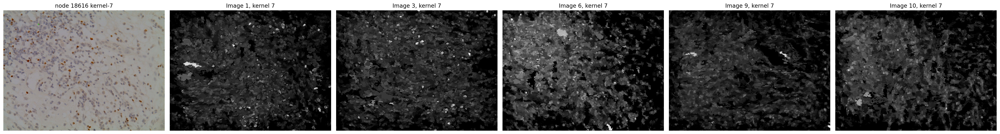

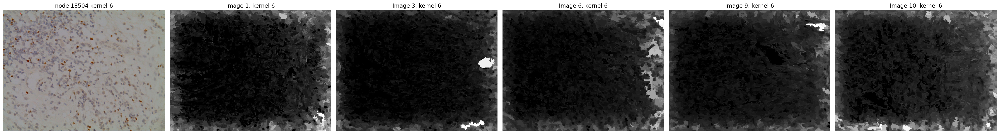

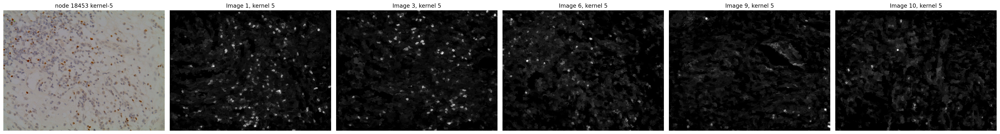

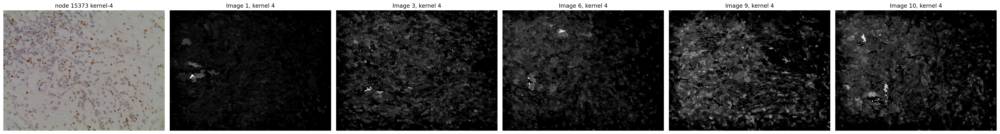

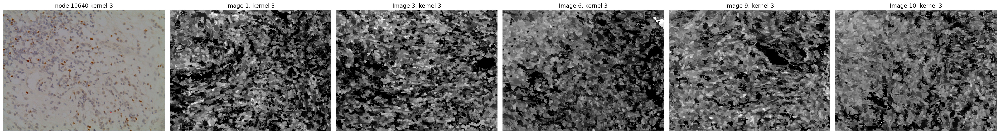

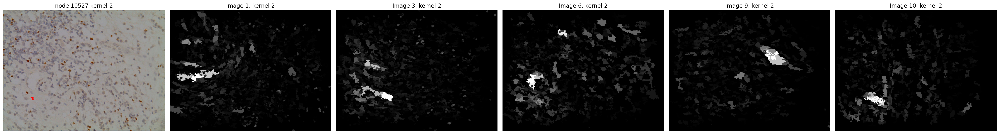

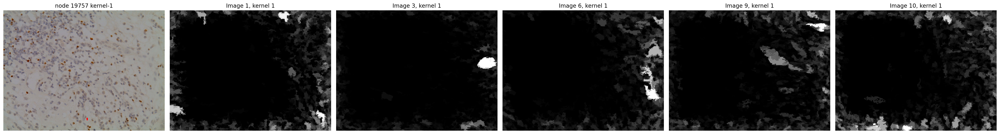

In [10]:
# results from the model directory

spxs_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/DISF/50000-20000/SUM/labels'
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}/results_semi_automatic/iteration_4'
train_img = '6'
marker_file = f'{model_dir}/markers/6-seeds_graph.txt'
spxs_img_file = f'{spxs_img_path}/{train_img}.pgm'
orig_img_file = f'{DATASET_PATH}/splits/split{SPLIT_ID}/orig/train/{train_img}.png'
# shows one markers per row

# read markers
with open(marker_file, 'r') as file:
    data = file.readlines()
    nmarkers = int(data[0].strip().split(" ")[0])
    markers = [tuple(map(int, line.strip().split(" "))) for line in data[1:nmarkers+1]]

orig_img = Image.open(orig_img_file) # read orig_img
spx_img = np.array(Image.open(spxs_img_file))  # read superpixel img

for marker_id, marker in enumerate(markers):
    labeled_node, __, label = marker  # select the current marker
    label += 1

    # colorize one marker in the original image
    colorized_img = np.array(orig_img.copy())
    colorized_img = colorized_img.astype(np.uint8)
    pixels = np.where(spx_img == labeled_node+1)
    colorized_img[pixels] = [255, 0, 0] if label == 1 else [0, 255, 0]  # colorize in red or green

    # read the kernel related to this marker for each image
    kernels_folder = f'{model_dir}/activation1/label{label}'
    img_names = listdir(kernels_folder)
    kernel_id = len(markers) - marker_id

    # plot a row of images with the colorized image and the kernel images
    fig, ax = plt.subplots(1, len([1,3,6,9,10])+1, figsize=(30, 30), dpi=200)
    ax[0].set_title(f'node {labeled_node} kernel-{kernel_id}')
    ax[0].imshow(colorized_img)
    ax[0].axis('off')

    for i, img_name in enumerate([1,3,6,9,10]):
        kernel_img = Image.open(f'{kernels_folder}/{img_name}/kernel-{kernel_id:0>3}.pgm')
        kernel_img = np.array(kernel_img)
        ax[i + 1].imshow(kernel_img, cmap='gray')
        ax[i + 1].set_title(f'Image {img_name}, kernel {kernel_id}')
        ax[i + 1].axis('off')

    plt.tight_layout()


In [7]:
# results from iteration 1

spxs_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/DISF/50000-20000/SUM/labels'
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}/results_semi_automatic/iteration_1'
train_img = '6'
marker_file = f'{model_dir}/markers/6-seeds_graph.txt'
spxs_img_file = f'{spxs_img_path}/{train_img}.pgm'
orig_img_file = f'{DATASET_PATH}/splits/split{SPLIT_ID}/orig/train/{train_img}.png'
# shows one markers per row

# read markers
with open(marker_file, 'r') as file:
    data = file.readlines()
    nmarkers = int(data[0].strip().split(" ")[0])
    markers = [tuple(map(int, line.strip().split(" "))) for line in data[1:nmarkers+1]]

orig_img = Image.open(orig_img_file) # read orig_img
spx_img = np.array(Image.open(spxs_img_file))  # read superpixel img

for marker_id, marker in enumerate(markers):
    labeled_node, __, label = marker  # select the current marker
    label += 1

    # colorize one marker in the original image
    colorized_img = np.array(orig_img.copy())
    colorized_img = colorized_img.astype(np.uint8)
    pixels = np.where(spx_img == labeled_node+1)
    colorized_img[pixels] = [255, 0, 0] if label == 1 else [0, 255, 0]  # colorize in red or green

    # read the kernel related to this marker for each image
    kernels_folder = f'{model_dir}/activation1/label{label}'
    img_names = listdir(kernels_folder)
    kernel_id = len(markers) - marker_id

    # plot a row of images with the colorized image and the kernel images
    fig, ax = plt.subplots(1, len([1,3,6,9,10])+1, figsize=(30, 30), dpi=200)
    ax[0].set_title(f'node {labeled_node} kernel-{kernel_id}')
    ax[0].imshow(colorized_img)
    ax[0].axis('off')

    for i, img_name in enumerate([1,3,6,9,10]):
        kernel_img = Image.open(f'{kernels_folder}/{img_name}/kernel-{kernel_id:0>3}.pgm')
        kernel_img = np.array(kernel_img)
        ax[i + 1].imshow(kernel_img, cmap='gray')
        ax[i + 1].set_title(f'Image {img_name}, kernel {kernel_id}')
        ax[i + 1].axis('off')

    plt.tight_layout()


NameError: name 'DS_NAME' is not defined

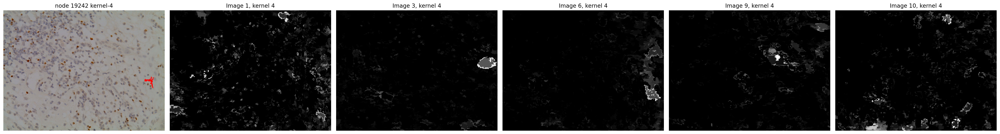

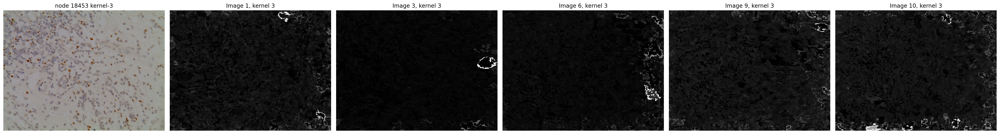

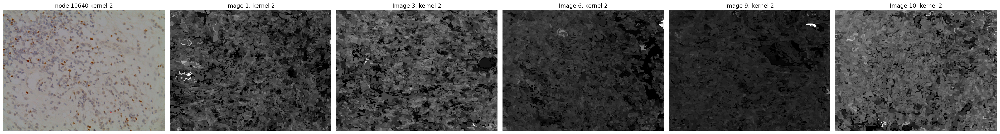

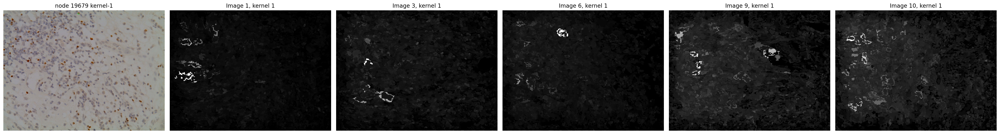

In [103]:
# results from iteration 2

spxs_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/DISF/50000-20000/SUM/labels'
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}/results_semi_automatic/iteration_2'
train_img = '6'
marker_file = f'{model_dir}/markers/6-seeds_graph.txt'
spxs_img_file = f'{spxs_img_path}/{train_img}.pgm'
orig_img_file = f'{DATASET_PATH}/splits/split{SPLIT_ID}/orig/train/{train_img}.png'
# shows one markers per row

# read markers
with open(marker_file, 'r') as file:
    data = file.readlines()
    nmarkers = int(data[0].strip().split(" ")[0])
    markers = [tuple(map(int, line.strip().split(" "))) for line in data[1:nmarkers+1]]

orig_img = Image.open(orig_img_file) # read orig_img
spx_img = np.array(Image.open(spxs_img_file))  # read superpixel img

for marker_id, marker in enumerate(markers):
    labeled_node, __, label = marker  # select the current marker
    label += 1

    # colorize one marker in the original image
    colorized_img = np.array(orig_img.copy())
    colorized_img = colorized_img.astype(np.uint8)
    pixels = np.where(spx_img == labeled_node+1)
    colorized_img[pixels] = [255, 0, 0] if label == 1 else [0, 255, 0]  # colorize in red or green

    # read the kernel related to this marker for each image
    kernels_folder = f'{model_dir}/activation1/label{label}'
    img_names = listdir(kernels_folder)
    kernel_id = len(markers) - marker_id

    # plot a row of images with the colorized image and the kernel images
    fig, ax = plt.subplots(1, len([1,3,6,9,10])+1, figsize=(30, 30), dpi=200)
    ax[0].set_title(f'node {labeled_node} kernel-{kernel_id}')
    ax[0].imshow(colorized_img)
    ax[0].axis('off')

    for i, img_name in enumerate([1,3,6,9,10]):
        kernel_img = Image.open(f'{kernels_folder}/{img_name}/kernel-{kernel_id:0>3}.pgm')
        kernel_img = np.array(kernel_img)
        ax[i + 1].imshow(kernel_img, cmap='gray')
        ax[i + 1].set_title(f'Image {img_name}, kernel {kernel_id}')
        ax[i + 1].axis('off')

    plt.tight_layout()


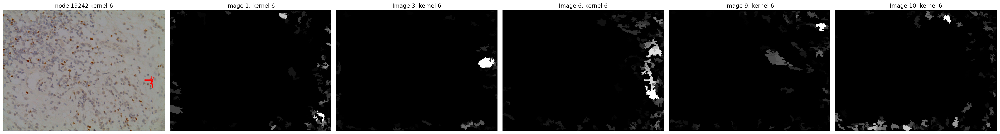

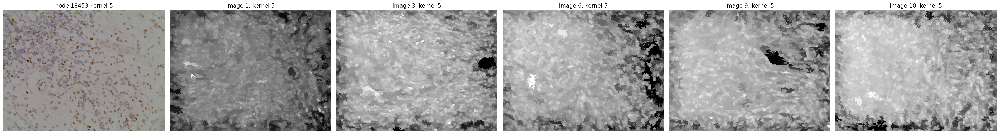

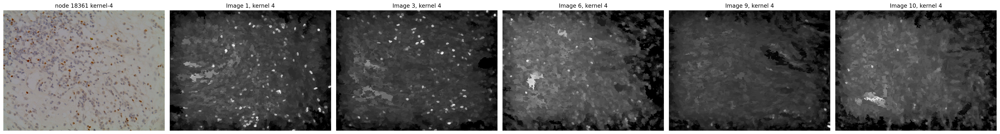

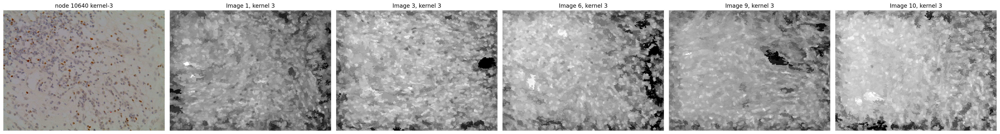

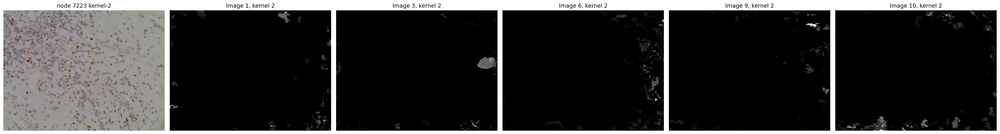

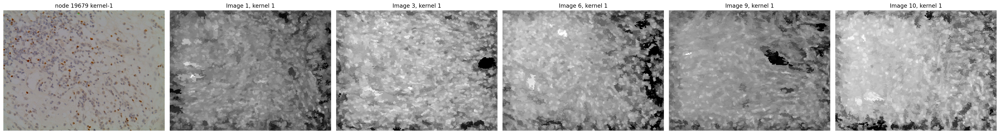

In [104]:
# results from iteration 3

spxs_img_path = '/home/isabela/Codes/LibIFT/Datasets/cells_dataset/superpixels/DISF/50000-20000/SUM/labels'
model_dir = f'/home/isabela/Codes/LibIFT/Results/{DS_NAME}/split{SPLIT_ID}/{MARKERS_NAME}/{ARCH_NAME}/gflim-BoFP/{STRIDE}/{SPX_ALG}/{INIT_SEEDS}-{FINAL_SPX}/{CONFIG}/{GRAPH_FEATS}-{ATTENTION}/results_semi_automatic/iteration_3'
train_img = '6'
marker_file = f'{model_dir}/markers/6-seeds_graph.txt'
spxs_img_file = f'{spxs_img_path}/{train_img}.pgm'
orig_img_file = f'{DATASET_PATH}/splits/split{SPLIT_ID}/orig/train/{train_img}.png'
# shows one markers per row

# read markers
with open(marker_file, 'r') as file:
    data = file.readlines()
    nmarkers = int(data[0].strip().split(" ")[0])
    markers = [tuple(map(int, line.strip().split(" "))) for line in data[1:nmarkers+1]]

orig_img = Image.open(orig_img_file) # read orig_img
spx_img = np.array(Image.open(spxs_img_file))  # read superpixel img

for marker_id, marker in enumerate(markers):
    labeled_node, __, label = marker  # select the current marker
    label += 1

    # colorize one marker in the original image
    colorized_img = np.array(orig_img.copy())
    colorized_img = colorized_img.astype(np.uint8)
    pixels = np.where(spx_img == labeled_node+1)
    colorized_img[pixels] = [255, 0, 0] if label == 1 else [0, 255, 0]  # colorize in red or green

    # read the kernel related to this marker for each image
    kernels_folder = f'{model_dir}/activation1/label{label}'
    img_names = listdir(kernels_folder)
    kernel_id = len(markers) - marker_id

    # plot a row of images with the colorized image and the kernel images
    fig, ax = plt.subplots(1, len([1,3,6,9,10])+1, figsize=(30, 30), dpi=200)
    ax[0].set_title(f'node {labeled_node} kernel-{kernel_id}')
    ax[0].imshow(colorized_img)
    ax[0].axis('off')

    for i, img_name in enumerate([1,3,6,9,10]):
        kernel_img = Image.open(f'{kernels_folder}/{img_name}/kernel-{kernel_id:0>3}.pgm')
        kernel_img = np.array(kernel_img)
        ax[i + 1].imshow(kernel_img, cmap='gray')
        ax[i + 1].set_title(f'Image {img_name}, kernel {kernel_id}')
        ax[i + 1].axis('off')

    plt.tight_layout()


In [ ]:
6,7,8,11,12,15,16,18,19,20,21,24,25